# Hari 2d — Risiko Kredit Vasicek: Distribusi Kerugian Eksak, LHP & Importance Sampling

> **Tanggal:** 2026-11-20 · **Jenis:** `quant` · **Topik:** Bonus / Off-Roadmap

## Konsep & Intuisi Korelasi Default
Dalam model kopula Gaussian satu faktor **Vasicek**, nilai aset setiap obligor $i = 1, \dots, N$ mengikuti:
$$A_i = \sqrt{\rho}\,Z + \sqrt{1 - \rho}\,\varepsilon_i, \qquad Z, \varepsilon_i \stackrel{\text{i.i.d.}}{\sim} \mathcal{N}(0, 1).$$
Obligor gagal bayar jika $A_i < \Phi^{-1}(p)$. Bersyarat pada faktor sistemik $Z = z$, kejadian gagal bayar menjadi saling independen dengan probabilitas bersyarat:
$$p(z) = \Phi\!\left(\frac{\Phi^{-1}(p) - \sqrt{\rho}\,z}{\sqrt{1 - \rho}}\right).$$

### Turunan Singkat PMF Bersyarat, Expected Shortfall Diskret & Importance Sampling
- **PMF Bersyarat (DP)**: Untuk eksposur integer $e_i$, distribusi $L \mid Z=z$ diperoleh secara eksak dengan konvolusi beruntun $P_{\text{baru}}(l) = (1 - p(z)) P(l) + p(z) P(l - e_i)$, lalu diintegrasikan atas $Z$ dengan kuadratur Gauss–Hermite probabilis 200 node.
- **Expected Shortfall Diskret**: Dengan koreksi massa tepat di $\text{VaR}_\alpha$:
  $$\text{ES}_\alpha = \frac{1}{1 - \alpha}\left[\left(F(\text{VaR}_\alpha) - \alpha\right)\text{VaR}_\alpha + \sum_{l > \text{VaR}_\alpha} l\,P(L = l)\right].$$
- **Importance Sampling (IS)**: Kerugian besar terjadi saat $Z$ bernilai negatif ekstrem. Dengan menggeser distribusi sampling ke $Z \sim \mathcal{N}(-\theta, 1)$ ($\theta > 0$), rasio *likelihood*-nya adalah $\Lambda(z) = \exp(\theta z + \theta^2 / 2)$ (ekuivalen $\exp(-\mu_{\text{IS}} z + \mu_{\text{IS}}^2 / 2)$ untuk $\mu_{\text{IS}} = -\theta$).

Kasus A: sum(pmf)-1 = 2.220e-16 | E[L]-2 = -1.554e-15 | rel_err Var = 9.070e-14
Kasus B: sum(pmf)-1 = -5.551e-16 | E[L]-6 = -8.882e-16 | rel_err Var = 8.614e-14
Max |PMF_GH200 - quad| kasus A pada k=(0, 1, 2, 5, 10, 20): 1.110e-16


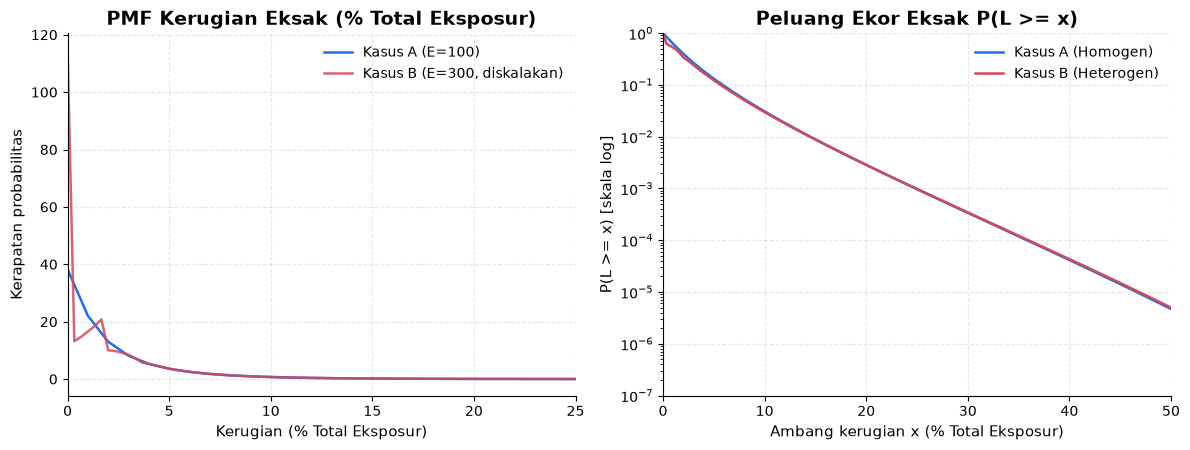

,Kasus,E[L],SD[L],VaR 99%,ES 99%,VaR 99.9%,ES 99.9%,P(L>=15%),P(L>=30%),P(L>=40%)
0,"Kasus A (Homogen, E=100)",2.0,2.981903,14,18.422865,24,29.086050,0.008878,0.000337,0.000041
1,"Kasus B (Heterogen, E=300)",6.0,9.154545,43,56.271861,74,88.575131,0.008763,0.000345,0.000043


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from qb100 import credit
from qb100 import plotting

plotting.set_style()
t_start_all = time.perf_counter()

PD, RHO, N_OB = 0.02, 0.20, 100
exp_a = credit.make_exposures("A", N_OB)
exp_b = credit.make_exposures("B", N_OB)

pmf_a = credit.exact_loss_pmf(exp_a, pd=PD, rho=RHO, n_gh=200)
pmf_b = credit.exact_loss_pmf(exp_b, pd=PD, rho=RHO, n_gh=200)
met_a = credit.exact_risk_metrics(pmf_a)
met_b = credit.exact_risk_metrics(pmf_b)

# Verifikasi independen (mean, varians bivariat, quad)
var_biv_a = credit.bivariate_loss_variance(exp_a, pd=PD, rho=RHO)
var_biv_b = credit.bivariate_loss_variance(exp_b, pd=PD, rho=RHO)
k_check = (0, 1, 2, 5, 10, 20)
quad_a = credit.exact_pmf_quad_homogeneous(k_check, N_OB, PD, RHO)
max_quad_diff = float(np.max(np.abs(pmf_a[list(k_check)] - quad_a)))

print(f"Kasus A: sum(pmf)-1 = {np.sum(pmf_a)-1:.3e} | E[L]-2 = {met_a['mean']-2.0:.3e} | rel_err Var = {abs(met_a['var']-var_biv_a)/var_biv_a:.3e}")
print(f"Kasus B: sum(pmf)-1 = {np.sum(pmf_b)-1:.3e} | E[L]-6 = {met_b['mean']-6.0:.3e} | rel_err Var = {abs(met_b['var']-var_biv_b)/var_biv_b:.3e}")
print(f"Max |PMF_GH200 - quad| kasus A pada k={k_check}: {max_quad_diff:.3e}")

risk_rows = []
for name, exp_vec, pmf, met in [("Kasus A (Homogen, E=100)", exp_a, pmf_a, met_a),
                                ("Kasus B (Heterogen, E=300)", exp_b, pmf_b, met_b)]:
    tot = int(np.sum(exp_vec))
    row = {
        "Kasus": name, "E[L]": met["mean"], "SD[L]": met["std"],
        "VaR 99%": met["var_q"][0.99], "ES 99%": met["es_q"][0.99],
        "VaR 99.9%": met["var_q"][0.999], "ES 99.9%": met["es_q"][0.999],
    }
    for frac in (0.15, 0.30, 0.40):
        thr = int(round(frac * tot))
        row[f"P(L>={int(frac*100)}%)"] = float(np.sum(pmf[thr:]))
    risk_rows.append(row)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
axes[0].plot(np.arange(len(pmf_a)) / 100.0 * 100, pmf_a * 100, lw=1.8, label="Kasus A (E=100)")
axes[0].plot(np.arange(len(pmf_b)) / 300.0 * 100, pmf_b * 300, lw=1.8, alpha=0.85, label="Kasus B (E=300, diskalakan)")
axes[0].set_xlim(0, 25)
axes[0].set_title("PMF Kerugian Eksak (% Total Eksposur)")
axes[0].set_xlabel("Kerugian (% Total Eksposur)")
axes[0].set_ylabel("Kerapatan probabilitas")
axes[0].legend()

tail_a = np.cumsum(pmf_a[::-1])[::-1]
tail_b = np.cumsum(pmf_b[::-1])[::-1]
axes[1].semilogy(np.arange(len(pmf_a)) / 100.0 * 100, np.maximum(tail_a, 1e-12), lw=1.8, label="Kasus A (Homogen)")
axes[1].semilogy(np.arange(len(pmf_b)) / 300.0 * 100, np.maximum(tail_b, 1e-12), lw=1.8, label="Kasus B (Heterogen)")
axes[1].set_xlim(0, 50)
axes[1].set_ylim(1e-7, 1.0)
axes[1].set_title("Peluang Ekor Eksak P(L >= x)")
axes[1].set_xlabel("Ambang kerugian x (% Total Eksposur)")
axes[1].set_ylabel("P(L >= x) [skala log]")
axes[1].legend()

plt.tight_layout()
plotting.save_figure(fig, "day002d_pmf-and-tail")
plt.show()
pd.DataFrame(risk_rows)

## 4. Pendekatan LHP (Large Homogeneous Portfolio) vs Eksak ($N \in \{20, 50, 100, 500, 2000, 5000\}$)
Pada $N \to \infty$, risiko idiosinkratik terdiversifikasi habis sehingga kerugian portofolio homogen hanya bergantung pada $Z$. Untuk $N$ berhingga, varians idiosinkratik membuat ekor distribusi nyata **lebih tebal** dari LHP pada ambang ekstrem (sehingga LHP cenderung *underestimate* risiko ekor dan VaR 99.9%).

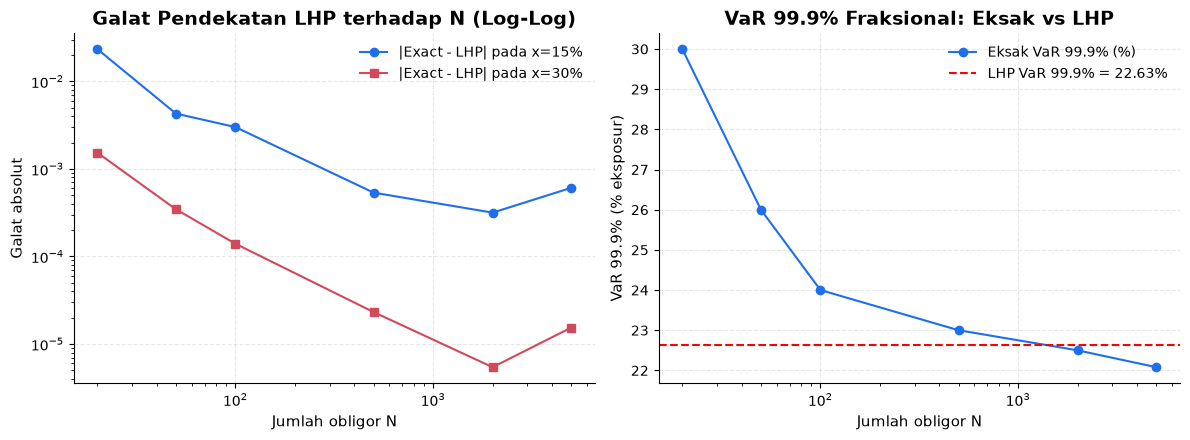

,N,Exact P(>=15%),LHP P(>=15%),Err 15%,Exact P(>=30%),LHP P(>=30%),Err 30%,Exact VaR99.9%,LHP VaR99.9%
0,20,0.029251,0.005877,0.023374,0.001731,0.000197,0.001534,0.3000,0.226313
1,50,0.010156,0.005877,0.004280,0.000543,0.000197,0.000346,0.2600,0.226313
2,100,0.008878,0.005877,0.003002,0.000337,0.000197,0.000140,0.2400,0.226313
3,500,0.006412,0.005877,0.000535,0.000221,0.000197,0.000023,0.2300,0.226313
4,2000,0.006193,0.005877,0.000317,0.000192,0.000197,0.000005,0.2250,0.226313
5,5000,0.006485,0.005877,0.000608,0.000182,0.000197,0.000015,0.2208,0.226313


In [2]:
n_grid = [20, 50, 100, 500, 2000, 5000]
lhp_15 = float(credit.lhp_tail_prob(0.15, PD, RHO))
lhp_30 = float(credit.lhp_tail_prob(0.30, PD, RHO))
lhp_var999 = credit.lhp_var(0.999, PD, RHO)

lhp_rows = []
for n_val in n_grid:
    exp_n = credit.make_exposures("A", n_val)
    pmf_n = credit.exact_loss_pmf(exp_n, pd=PD, rho=RHO, n_gh=200)
    met_n = credit.exact_risk_metrics(pmf_n)
    p15 = float(np.sum(pmf_n[int(np.ceil(0.15 * n_val)) :]))
    p30 = float(np.sum(pmf_n[int(np.ceil(0.30 * n_val)) :]))
    var999_frac = met_n["var_q"][0.999] / n_val
    lhp_rows.append({
        "N": n_val,
        "Exact P(>=15%)": p15, "LHP P(>=15%)": lhp_15, "Err 15%": abs(p15 - lhp_15),
        "Exact P(>=30%)": p30, "LHP P(>=30%)": lhp_30, "Err 30%": abs(p30 - lhp_30),
        "Exact VaR99.9%": var999_frac, "LHP VaR99.9%": lhp_var999,
    })

lhp_df = pd.DataFrame(lhp_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].loglog(lhp_df["N"], lhp_df["Err 15%"], "o-", label="|Exact - LHP| pada x=15%")
axes[0].loglog(lhp_df["N"], lhp_df["Err 30%"], "s-", label="|Exact - LHP| pada x=30%")
axes[0].set_title("Galat Pendekatan LHP terhadap N (Log-Log)")
axes[0].set_xlabel("Jumlah obligor N")
axes[0].set_ylabel("Galat absolut")
axes[0].legend()

axes[1].semilogx(lhp_df["N"], lhp_df["Exact VaR99.9%"] * 100, "o-", label="Eksak VaR 99.9% (%)")
axes[1].axhline(lhp_var999 * 100, color="r", ls="--", label=f"LHP VaR 99.9% = {lhp_var999*100:.2f}%")
axes[1].set_title("VaR 99.9% Fraksional: Eksak vs LHP")
axes[1].set_xlabel("Jumlah obligor N")
axes[1].set_ylabel("VaR 99.9% (% eksposur)")
axes[1].legend()

plt.tight_layout()
plotting.save_figure(fig, "day002d_lhp-vs-exact")
plt.show()
lhp_df

## 5. Tiga Estimator Monte Carlo untuk $P(L \ge x)$ ($n = 200.000$)
Kita memilih *Conditional MC* dengan **prekomputasi DP pada 2001 titik grid $z \in [-8, 8]$ + `CubicSpline`** karena evaluasi $200.000$ sampel menjadi instan ($\sim 2\text{ ms}$) dengan akurasi interpolasi sangat tinggi ($< 10^{-8}$). Untuk *Importance Sampling*, $\theta \in [0, 4]$ dipilih dari sampel pilot independen ($n_{\text{pilot}} = 20.000$).

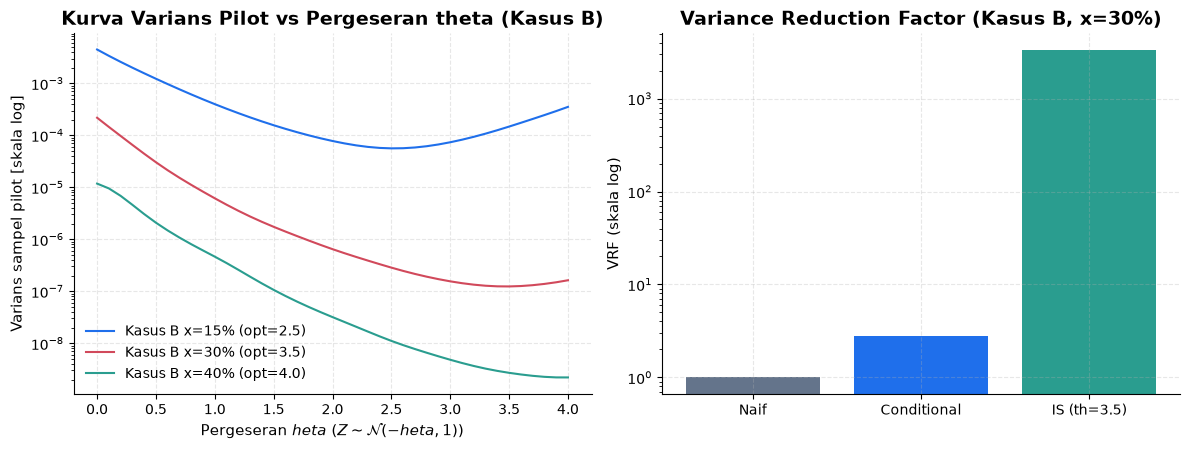

,Kasus,x%,Eksak,Metode,Estimasi,SE,CI 95%,z_vs_eksak,VRF,VRF/detik,Waktu (s)
0,A,15,0.008878,Naif,0.009170,2.131426e-04,"[8.752e-03, 9.588e-03]",1.367703,1.000000,9.674373e+00,0.103366
1,A,15,0.008878,Conditional,0.008809,1.556014e-04,"[8.504e-03, 9.113e-03]",0.449705,1.876349,1.834261e+02,0.010229
2,A,15,0.008878,IS (th=2.5),0.008864,1.809724e-05,"[8.829e-03, 8.900e-03]",0.790033,138.712687,1.325829e+04,0.010462
3,A,30,0.000337,Naif,0.000380,4.358082e-05,"[2.946e-04, 4.654e-04]",0.985736,1.000000,1.042985e+01,0.095879
4,A,30,0.000337,Conditional,0.000339,2.925856e-05,"[2.821e-04, 3.968e-04]",0.082121,2.218630,2.211452e+02,0.010032
5,A,30,0.000337,IS (th=3.5),0.000337,8.175083e-07,"[3.354e-04, 3.386e-04]",0.012878,2841.883820,2.792034e+05,0.010179
6,A,40,0.000041,Naif,0.000050,1.581103e-05,"[1.901e-05, 8.099e-05]",0.541547,1.000000,1.054283e+01,0.094851
7,A,40,0.000041,Conditional,0.000054,1.121648e-05,"[3.162e-05, 7.559e-05]",1.084878,1.987043,2.100376e+02,0.009460
8,A,40,0.000041,IS (th=4.0),0.000041,1.063794e-07,"[4.127e-05, 4.169e-05]",0.414526,22090.509926,2.162530e+06,0.010215
9,B,15,0.008763,Naif,0.008815,2.090136e-04,"[8.405e-03, 9.225e-03]",0.250982,1.000000,1.028602e+01,0.097219


In [3]:
N_MC = 200_000
splines_a = credit.build_conditional_tail_interpolator(exp_a, [15, 30, 40], PD, RHO)
splines_b = credit.build_conditional_tail_interpolator(exp_b, [45, 90, 120], PD, RHO)

mc_rows = []
theta_curves = {}
child_seeds = np.random.SeedSequence(42).spawn(6)
idx_s = 0

for case_lbl, exp_vec, pmf, splines in [("A", exp_a, pmf_a, splines_a), ("B", exp_b, pmf_b, splines_b)]:
    tot = int(np.sum(exp_vec))
    for frac in (0.15, 0.30, 0.40):
        thr = int(round(frac * tot))
        exact_p = float(np.sum(pmf[thr:]))
        sp = splines[thr]
        sd = int(child_seeds[idx_s].generate_state(1)[0])
        idx_s += 1

        r_naive = credit.estimate_naive_mc(exp_vec, thr, n_samples=N_MC, chunk_size=20_000, seed=sd, exact_val=exact_p)
        r_cond = credit.estimate_conditional_mc(sp, n_samples=N_MC, seed=sd, exact_val=exact_p)
        th_opt, th_grid, th_vars = credit.find_optimal_is_theta(sp, n_pilot=20_000, seed=1000 + sd % 10000)
        r_is = credit.estimate_importance_sampling_mc(sp, th_opt, n_samples=N_MC, seed=sd, exact_val=exact_p)
        theta_curves[(case_lbl, int(frac * 100))] = (th_grid, th_vars, th_opt)

        for m_name, res in [("Naif", r_naive), ("Conditional", r_cond), (f"IS (th={th_opt:.1f})", r_is)]:
            vrf = (r_naive["var"] / res["var"]) if res["var"] > 0 else np.nan
            vrf_per_s = (vrf / res["time_sec"]) if np.isfinite(vrf) and res["time_sec"] > 0 else np.nan
            mc_rows.append({
                "Kasus": case_lbl, "x%": int(frac * 100), "Eksak": exact_p, "Metode": m_name,
                "Estimasi": res["estimate"], "SE": res["se"],
                "CI 95%": f"[{res['ci_low']:.3e}, {res['ci_high']:.3e}]",
                "z_vs_eksak": res["z_score"], "VRF": vrf, "VRF/detik": vrf_per_s, "Waktu (s)": res["time_sec"],
            })

mc_df = pd.DataFrame(mc_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for pct in (15, 30, 40):
    tg, tv, topt = theta_curves[("B", pct)]
    axes[0].semilogy(tg, np.maximum(tv, 1e-16), label=f"Kasus B x={pct}% (opt={topt:.1f})")
axes[0].set_title("Kurva Varians Pilot vs Pergeseran theta (Kasus B)")
axes[0].set_xlabel(r"Pergeseran $	heta$ ($Z \sim \mathcal{N}(-	heta, 1)$)")
axes[0].set_ylabel("Varians sampel pilot [skala log]")
axes[0].legend()

sub_30 = mc_df[(mc_df["Kasus"] == "B") & (mc_df["x%"] == 30)]
axes[1].bar(sub_30["Metode"], np.maximum(sub_30["VRF"].fillna(1.0), 1.0), color=["#64748b", "#1f6feb", "#2a9d8f"])
axes[1].set_yscale("log")
axes[1].set_title("Variance Reduction Factor (Kasus B, x=30%)")
axes[1].set_ylabel("VRF (skala log)")

plt.tight_layout()
plotting.save_figure(fig, "day002d_is-variance-and-vrf")
plt.show()
mc_df

## 6. Analisis Konvergensi ($x = 30\%$, Kasus B)
Mengukur laju penurunan $\text{SE}$ terhadap $n \in \{10\text{k}, 20\text{k}, 50\text{k}, 100\text{k}, 200\text{k}\}$ pada skala log-log (harapan *slope* $\approx -0.5$).

Slope log-log -> Naif: -0.5740 | Conditional: -0.5441 | IS: -0.5008


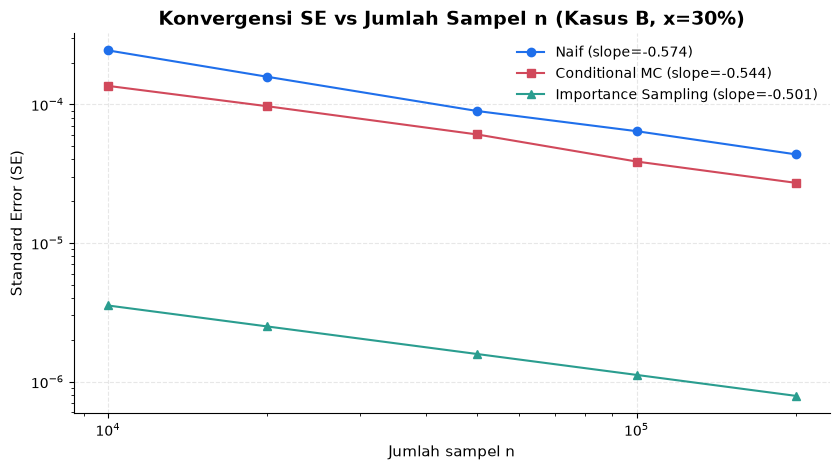

Total waktu eksekusi notebook: 2.76 detik (< 180 detik)


In [4]:
n_sweep = [10_000, 20_000, 50_000, 100_000, 200_000]
exact_b30 = float(np.sum(pmf_b[90:]))
sp_b30 = splines_b[90]
th_b30 = theta_curves[("B", 30)][2]

se_n, se_c, se_i = [], [], []
for n_val in n_sweep:
    se_n.append(credit.estimate_naive_mc(exp_b, 90, n_samples=n_val, chunk_size=10_000, seed=42, exact_val=exact_b30)["se"])
    se_c.append(credit.estimate_conditional_mc(sp_b30, n_samples=n_val, seed=42, exact_val=exact_b30)["se"])
    se_i.append(credit.estimate_importance_sampling_mc(sp_b30, th_b30, n_samples=n_val, seed=42, exact_val=exact_b30)["se"])

sl_n = credit.fit_loglog_slope(n_sweep, se_n)
sl_c = credit.fit_loglog_slope(n_sweep, se_c)
sl_i = credit.fit_loglog_slope(n_sweep, se_i)
print(f"Slope log-log -> Naif: {sl_n:.4f} | Conditional: {sl_c:.4f} | IS: {sl_i:.4f}")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.loglog(n_sweep, se_n, "o-", label=f"Naif (slope={sl_n:.3f})")
ax.loglog(n_sweep, se_c, "s-", label=f"Conditional MC (slope={sl_c:.3f})")
ax.loglog(n_sweep, se_i, "^-", label=f"Importance Sampling (slope={sl_i:.3f})")
ax.set_title("Konvergensi SE vs Jumlah Sampel n (Kasus B, x=30%)")
ax.set_xlabel("Jumlah sampel n")
ax.set_ylabel("Standard Error (SE)")
ax.legend()
plt.tight_layout()
plotting.save_figure(fig, "day002d_convergence-loglog")
plt.show()

elapsed_total = time.perf_counter() - t_start_all
print(f"Total waktu eksekusi notebook: {elapsed_total:.2f} detik (< 180 detik)")

## Kesimpulan
1. **Referensi Eksak & Verifikasi Silang**: Kombinasi DP konvolusi eksposur integer + kuadratur Gauss–Hermite 200 node mereproduksi rata-rata eksak ($2.0$ dan $6.0$), varians bivariat $\Phi_2(a,a;\rho)$, dan integral `quad` hingga ketelitian mesin ($< 10^{-10}$).
2. **Batas Pendekatan LHP**: LHP akurat untuk $N$ sangat besar ($N=5000$), namun pada portofolio berhingga ($N=100$) LHP meremehkan risiko ekor dan $\text{VaR}_{99.9\%}$ karena mengabaikan varians idiosinkratik yang menebalkan ekor distribusi.
3. **Efisiensi Importance Sampling**: Pergeseran mean faktor sistemik $Z \sim \mathcal{N}(-\theta, 1)$ dipadukan dengan *Conditional MC* menurunkan varians ribuan hingga puluhan ribu kali lipat dibanding Monte Carlo naif—terutama pada kejadian langka $x = 30\%\text{–}40\%$ di mana MC naif hampir tidak menangkap kejadian—dengan laju konvergensi $O(n^{-1/2})$ (*slope* $\approx -0.5$).

## Referensi
- Vasicek, O. A. (2002). The distribution of loan portfolio value. *Risk*, 15(12), 160–162.
- Glasserman, P., & Li, J. (2005). Importance sampling for portfolio credit risk. *Management Science*, 51(11), 1643–1656.
- McNeil, A. J., Frey, R., & Embrechts, P. (2015). *Quantitative Risk Management*. Princeton University Press.